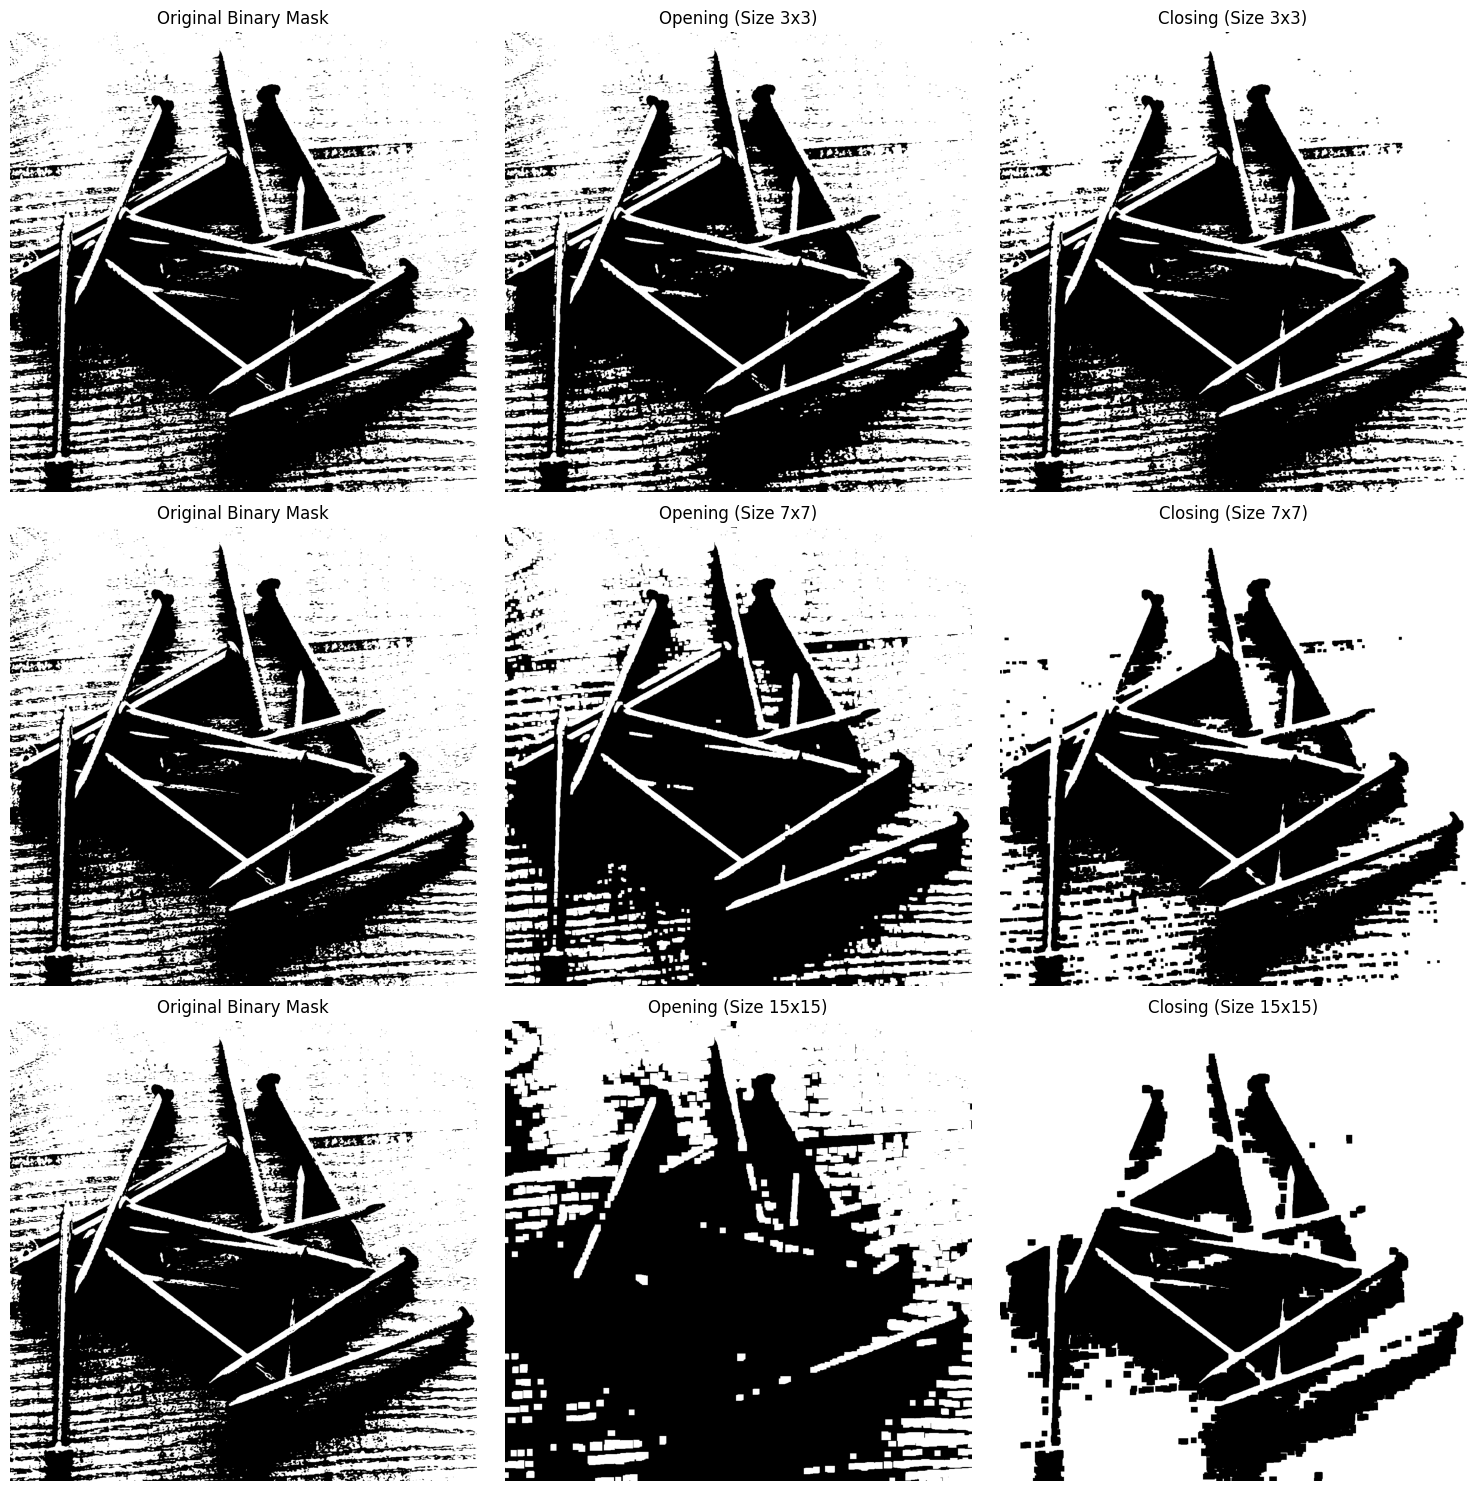

In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Create a synthetic industrial image if a real one isn't present
def get_inspection_image():
    # Create a dark background (200x200 pixels)
    img = np.zeros((200, 200), dtype=np.uint8)
    
    # Simulate a fragmented defect (a fractured line/crack)
    cv2.line(img, (40, 40), (80, 80), 255, 3)
    cv2.line(img, (90, 90), (150, 150), 255, 3) # Gap representing fragmentation
    
    # Add unwanted salt-and-pepper background noise (isolated spots)
    np.random.seed(42)
    noise_pixels_x = np.random.randint(0, 200, 50)
    noise_pixels_y = np.random.randint(0, 200, 50)
    img[noise_pixels_y, noise_pixels_x] = 255
    
    return img

# Load image (Attempts to read a local file 'defect.png', falls back to synthetic if not found)
gray_img = cv2.imread('crack.png', cv2.IMREAD_GRAYSCALE)
if gray_img is None:
    print("Local image 'defect.png' not found. Generating a synthetic industrial defect image...")
    binary_mask = get_inspection_image()
else:
    # Threshold local image to ensure it is binary
    _, binary_mask = cv2.threshold(gray_img, 127, 255, cv2.THRESH_BINARY)

# %%
# 2. Process with different Structuring Element (Kernel) sizes
kernel_sizes = [3, 7, 15]

fig, axes = plt.subplots(len(kernel_sizes), 3, figsize=(15, 5 * len(kernel_sizes)))

for i, size in enumerate(kernel_sizes):
    # Define a rectangular structuring element
    se = cv2.getStructuringElement(cv2.MORPH_RECT, (size, size))
    
    # Apply Opening: Erases small foreground noise / background speckles
    opened = cv2.morphologyEx(binary_mask, cv2.MORPH_OPEN, se)
    
    # Apply Closing: Bridges gaps / fuses fragmented defects together
    closed = cv2.morphologyEx(binary_mask, cv2.MORPH_CLOSE, se)
    
    # Visualizations
    if len(kernel_sizes) == 1:
        ax_row = axes
    else:
        ax_row = axes[i]
        
    ax_row[0].imshow(binary_mask, cmap='gray')
    ax_row[0].set_title("Original Binary Mask")
    ax_row[0].axis('off')
    
    ax_row[1].imshow(opened, cmap='gray')
    ax_row[1].set_title(f"Opening (Size {size}x{size})")
    ax_row[1].axis('off')
    
    ax_row[2].imshow(closed, cmap='gray')
    ax_row[2].set_title(f"Closing (Size {size}x{size})")
    ax_row[2].axis('off')

plt.tight_layout()
plt.show()
